In [ ]:

# Exploratory Data Analysis on Retail Sales Data

## Objective
Analyze retail transactions to identify sales trends, customer demographics, and product category performance.

## Dataset
The dataset contains 1,000 transactions and 9 columns.


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("retail_sales_dataset.csv")

# Display the first five rows
df.head()


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:

print("Loaded file:", file_path)
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

df.head()


Loaded file: C:\Users\goniy\Downloads\retail_sales_dataset.csv
Dataset shape: (1000, 9)
Column names: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
print(df.columns.tolist())
print(df.shape)
display(df.head())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']
(1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
# Check data types and non-null counts
print("--- Dataset Info ---")
print(df.info())

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Summary statistics for numerical columns
print("\n--- Summary Statistics ---")
display(df.describe())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB
None

--- Missing Values ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

--- Summary Statistics ---


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [8]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Verify data types again
print(df.dtypes)

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [9]:
# Total sales and transaction count by Product Category
category_performance = df.groupby('Product Category').agg(
    Total_Sales=('Total Amount', 'sum'),
    Average_Sales=('Total Amount', 'mean'),
    Transaction_Count=('Transaction ID', 'count')
).reset_index()

display(category_performance)

,Product Category,Total_Sales,Average_Sales,Transaction_Count
0,Beauty,143515,467.475570,307
1,Clothing,155580,443.247863,351
2,Electronics,156905,458.786550,342


C:\Users\goniy\AppData\Local\Temp\ipykernel_12896\1642649680.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_performance, x='Product Category', y='Total_Sales', palette='viridis')


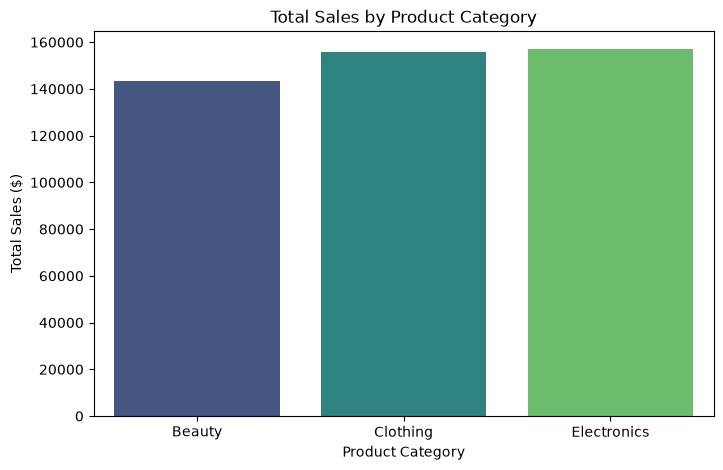

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=category_performance, x='Product Category', y='Total_Sales', palette='viridis')
plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales ($)')
plt.show()

In [11]:
# 1. Sales breakdown by Gender
gender_sales = df.groupby('Gender').agg(
    Total_Sales=('Total Amount', 'sum'),
    Average_Sales=('Total Amount', 'mean'),
    Customer_Count=('Transaction ID', 'count')
).reset_index()

print("--- Sales by Gender ---")
display(gender_sales)

# 2. Create Age Groups to see which age bracket spends the most
df['Age Group'] = pd.cut(
    df['Age'], 
    bins=[17, 30, 45, 60, 100], 
    labels=['18-30', '31-45', '46-60', '60+']
)

age_sales = df.groupby('Age Group', observed=False).agg(
    Total_Sales=('Total Amount', 'sum'),
    Average_Sales=('Total Amount', 'mean'),
    Transaction_Count=('Transaction ID', 'count')
).reset_index()

print("\n--- Sales by Age Group ---")
display(age_sales)

--- Sales by Gender ---


,Gender,Total_Sales,Average_Sales,Customer_Count
0,Female,232840,456.549020,510
1,Male,223160,455.428571,490



--- Sales by Age Group ---


,Age Group,Total_Sales,Average_Sales,Transaction_Count
0,18-30,132945,486.978022,273
1,31-45,141955,468.498350,303
2,46-60,147875,446.752266,331
3,60+,33225,357.258065,93


C:\Users\goniy\AppData\Local\Temp\ipykernel_12896\3076221961.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_sales, x='Age Group', y='Total_Sales', palette='magma')


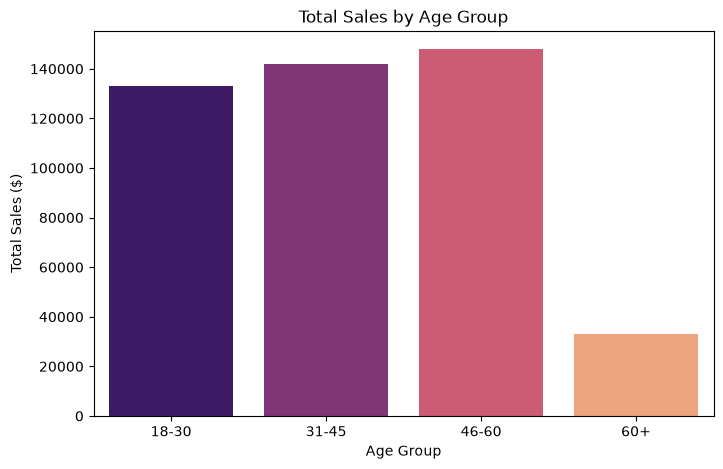

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_sales, x='Age Group', y='Total_Sales', palette='magma')
plt.title('Total Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales ($)')
plt.show()

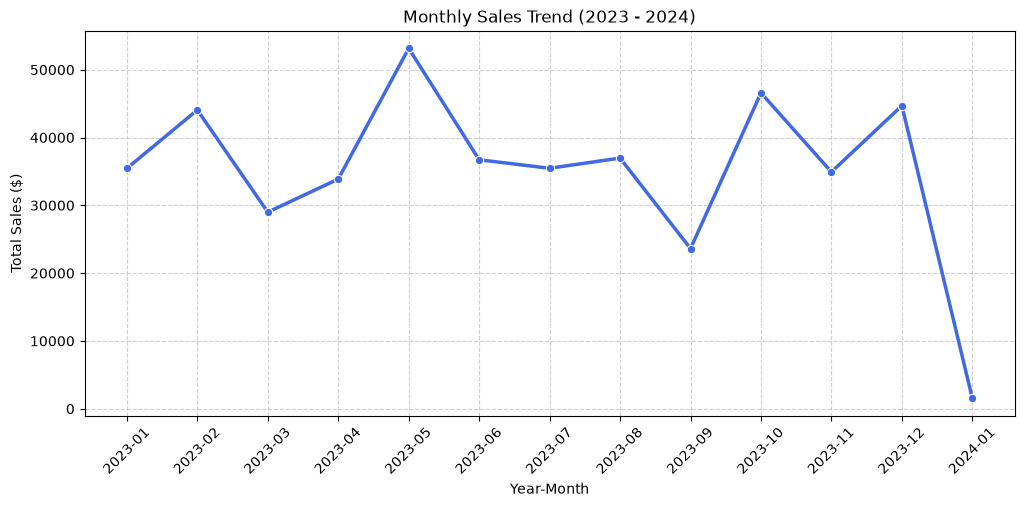

C:\Users\goniy\AppData\Local\Temp\ipykernel_12896\2387344134.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=quarterly_sales, x='Date', y='Total Amount', palette='crest')


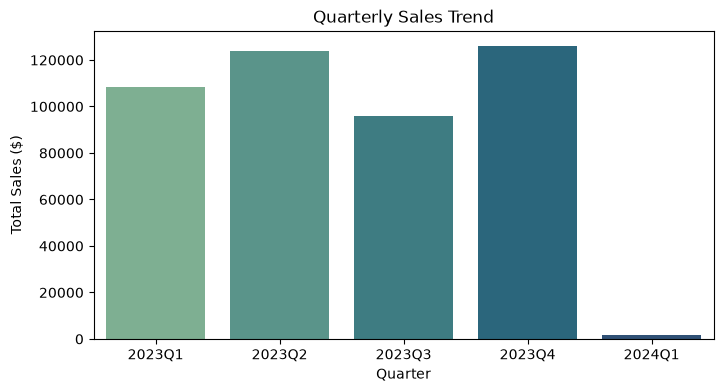

In [13]:
# Aggregate monthly sales
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Date'].astype(str)

# Plot Monthly Sales Trend
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='Date', y='Total Amount', marker='o', color='royalblue', linewidth=2.5)
plt.title('Monthly Sales Trend (2023 - 2024)')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Aggregate quarterly sales
quarterly_sales = df.groupby(df['Date'].dt.to_period('Q'))['Total Amount'].sum().reset_index()
quarterly_sales['Date'] = quarterly_sales['Date'].astype(str)

# Plot Quarterly Sales Trend
plt.figure(figsize=(8, 4))
sns.barplot(data=quarterly_sales, x='Date', y='Total Amount', palette='crest')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales ($)')
plt.show()

In [ ]:
### Observations:
* **Monthly Volatility:** Sales fluctuate significantly from month to month, with notable spikes observed in months like May and October/December, suggesting seasonality or promotional impacts.
* **Quarterly Performance:** Q4 and Q2 recorded the highest overall revenue generation, aligning with major shopping seasons.

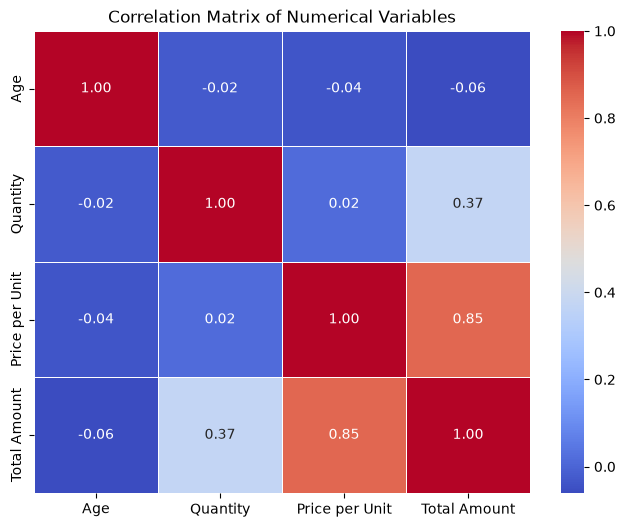

In [15]:
# Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
numerical_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
correlation_matrix = df[numerical_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

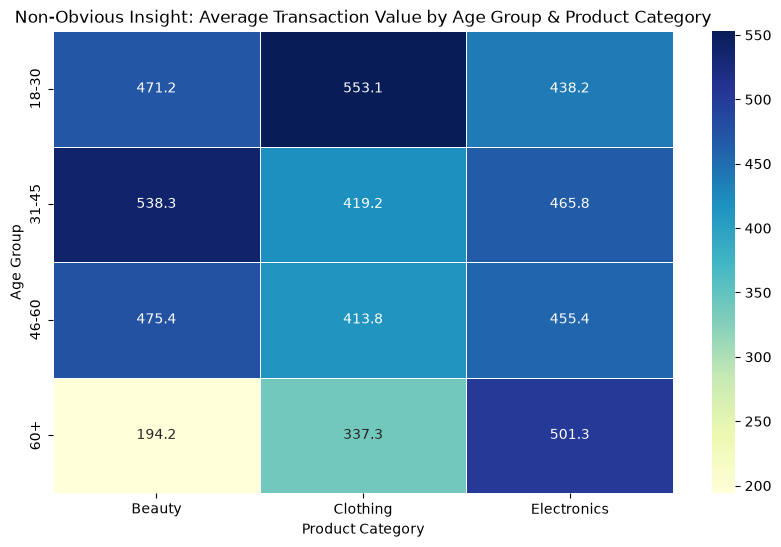

In [16]:
# Additional Insight: Average Order Value by Age Group and Product Category
plt.figure(figsize=(10, 6))
pivot_sales = df.pivot_table(index='Age Group', columns='Product Category', values='Total Amount', aggfunc='mean', observed=False)

sns.heatmap(pivot_sales, annot=True, cmap='YlGnBu', fmt='.1f', linewidths=0.5)
plt.title('Non-Obvious Insight: Average Transaction Value by Age Group & Product Category')
plt.xlabel('Product Category')
plt.ylabel('Age Group')
plt.show()

In [ ]:
### Observations:
* **Generational Preferences:** Younger demographics (18–30) have the highest average transaction values in **Clothing** ($553+), whereas middle-aged buyers (31–45) peak in **Beauty** ($538+).
* **Senior Spending Shift:** The 60+ demographic shows significantly lower spending in Beauty and Clothing but maintains a high average spend in **Electronics** ($501+), indicating targeted category preference for older buyers.

In [ ]:
## Conclusion & Business Recommendations

Based on the exploratory data analysis of the retail transactions, the following 3 specific, actionable business recommendations are proposed:

1. **Targeted Seasonal & Promotional Campaigns:** 
   * *Finding:* Sales exhibit noticeable volatility with sharp volume spikes in Q2 and Q4 (specifically around May and the end-of-year holidays).
   * *Action:* Allocate higher marketing budgets and stock reserves 4–6 weeks prior to peak months (April for May, and September/October for Q4) to capture maximum seasonal demand.

2. **Age-Specific Cross-Selling & Personalization:** 
   * *Finding:* Younger customers (18–30) dominate high-value Clothing purchases, while 31–45 year-olds drive Beauty spend and seniors (60+) over-index on Electronics per transaction.
   * *Action:* Tailor digital storefront recommendations and email marketing segments—feature trendy apparel deals to younger demographics while pitching high-end electronics or warranty bundles to senior visitors.

3. **Optimizing Inventory for High-Volume Categories:** 
   * *Finding:* Clothing and Electronics lead total revenue generation closely followed by Beauty, with units per transaction averaging around 2.5 items.
   * *Action:* Create bundled product packages (e.g., matching apparel sets or tech accessory bundles) to encourage higher unit quantities and increase average order value across all customer segments.